## Setup - load dataset and clean

In [1]:
import pandas as pd
import os

if os.path.exists('./parsed.csv'):
    df = pd.read_csv('./parsed.csv', engine="python", on_bad_lines="skip")
else:
    df = pd.read_csv('./dataset.csv', engine="python", on_bad_lines="skip")
print(df.shape)
df.head(10)

(64721, 8)


,Unnamed: 0,Message,Date Stamp,Date,Type,Title,Content,Link
0,0,0,"Sun, 07 May 2023 03:01:49 -0700",2023-05-07,News,Distributed Denial-Of-Service (DDoS) Protectio...,\r\nDistributed Denial-Of-Service (DDoS) Prote...,https://fylladey.com/2023/05/distributed-denia...
1,1,0,"Sun, 07 May 2023 03:01:49 -0700",2023-05-07,News,Building cyber resilience in HE needs everyone...,\r\nBuilding cyber resilience in HE needs ever...,https://www.universityworldnews.com/post.php%3...
2,2,0,"Sun, 07 May 2023 03:01:49 -0700",2023-05-07,News,DDos Saldırısı Nedir? Nasıl Koruma Sağlanır? -...,\r\nDDos Saldırısı Nedir? Nasıl Koruma Sağlanı...,https://www.basvur.co/haber/14921881/ddos-sald...
3,3,0,"Sun, 07 May 2023 03:01:49 -0700",2023-05-07,News,DDoS攻击洪水肆虐游戏企业如何抵挡？ - 硬派网,\r\nDDoS攻击洪水肆虐游戏企业如何抵挡？ - 硬派网\r\n硬派网\r\nDDoS攻击...,http://www.inpai.com.cn/news/redian/2023/0506/...
4,4,0,"Sun, 07 May 2023 03:01:49 -0700",2023-05-07,News,Google、5月14日のタイ総選挙を支援 | タイランドハイパーリンクス：Thai Hyper,\r\nGoogle、5月14日のタイ総選挙を支援 | タイランドハイパーリンクス：Thai...,https://www.thaich.net/news/20230507na.htm
5,5,0,"Sun, 07 May 2023 03:01:49 -0700",2023-05-07,News,헤어 브러시 시장 조사(2023-2028):성장 및 기타 측면에 대한 심층 평가 -,\r\n헤어 브러시 시장 조사(2023-2028):성장 및 기타 측면에 대한 심층 ...,https://www.imsil.tv/business/%25ED%2597%25A4%...
6,6,0,"Sun, 07 May 2023 03:01:49 -0700",2023-05-07,Web,美国ACCDON公司旗下品牌 - SCI论文修改,\r\n美国ACCDON公司旗下品牌 - SCI论文修改\r\n中英对照. 分布式拒绝服务....,http://letpub.com.cn/index.php%3Fpage%3Ddict%2...
7,7,1,"Wed, 10 May 2023 03:01:49 -0700",2023-05-10,News,US authorities seize more domains linked to pr...,\r\nUS authorities seize more domains linked t...,https://techcrunch.com/2023/05/09/us-authoriti...
8,8,1,"Wed, 10 May 2023 03:01:49 -0700",2023-05-10,News,U.S. Authorities Seize 13 Domains Offering Cri...,\r\nU.S. Authorities Seize 13 Domains Offering...,https://thehackernews.com/2023/05/us-authoriti...
9,9,1,"Wed, 10 May 2023 03:01:49 -0700",2023-05-10,News,Feds continue takedowns of DDoS-for-hire 'boot...,\r\nFeds continue takedowns of DDoS-for-hire '...,https://therecord.media/feds-seize-ddos-booter...


In [2]:
df = df.drop(columns=[c for c in ['Unnamed: 0', 'Date Stamp'] if c in df.columns])
df['Date'] = pd.to_datetime(df['Date'])

In [3]:
df.describe()

,Message,Date,elapsed_time
count,64721.000000,64721,32572.000000
mean,5063.012299,2021-07-27 18:57:21.862764800,6.930040
min,0.000000,2019-09-27 00:00:00,0.461965
25%,2404.000000,2020-09-26 00:00:00,1.521562
50%,4995.000000,2021-06-20 00:00:00,2.548170
75%,7704.000000,2022-05-29 00:00:00,3.658952
max,10377.000000,2023-05-10 00:00:00,7789.084516
std,3044.794573,NaN,117.847269


<Axes: title={'center': 'Distribution of Attack Types'}, xlabel='Type'>

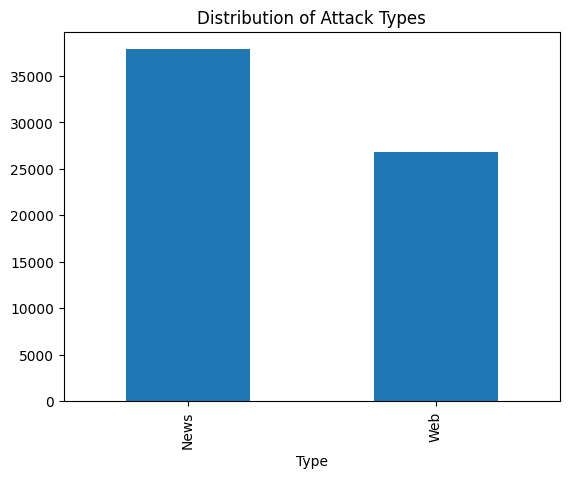

In [4]:
df['Type'].value_counts().plot(kind='bar', title='Distribution of Attack Types')

## Set up LLM extraction

In [5]:
import os
from datetime import datetime
import json
import re

from lingua import Language, LanguageDetectorBuilder

from difflib import SequenceMatcher


#for LLM extraction
import ollama

In [6]:
pip install lingua-language-detector

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
pip install ollama

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
detector = LanguageDetectorBuilder.from_all_languages().build()

In [9]:
# Ollama configuration
options = {
    'temperature': 0,
    'top_p': 1,
    'top_k' : 0,
    'seed': 1234,
    'num_ctx': 8192
}

model = 'qwen3:8b'

In [10]:
prompt = """
You are a cyber intelligence analyst with 20 years of experience in the the field.

Your task is to extract any entity from the input text. For each entity found you MUST indicate the type in UPPERCASE. ONLY extract entities if literal entity is present in input text.
The expected entity types are the following:

- VITCIM: Organizations, companies, institutions, and other entities that are victims of cyber attacks (for example Microsoft, Google, University of Twente) EXCLUDE any other entity type
- COST: Monetary values to indicate the cost of a cyber attack (for example $100, 100 USD, 100 EUR) EXCLUDE any other entity type
- IP: IP addresses (IPv4 x.x.x.x or IPv6)
- PERSON: Person Names of the attackers can also be Nick names 
- GROUP: Group names (for example Anonymous, Lizard Squad, APT28) EXCLUDE any other entity type
- LOCATION: cities, countries, geographic locations
- URL: URLs and web addresses EXCLUDE filenames
- MOTIVE: The motive of the attack CHOOSE FROM financial gain, espionage, hacktivism

 
**Output**:
The output MUST be in a JSON object with key 'entities' and the value a list of dictionaries including every entity found. For each entity you MUST indicate the type in UPPERCASE.

**OUTPUT EXAMPLE**:
{
  "entities": [
    {"entity": "Microsoft", "type": "VITCIM"},
    {"entity": "100,000 USD", "type": "COST"},
    {"entity": "Thompson", "type": "PERSON"},
    {"entity": "Helsinki", "type": "LOCATION"},
    {"entity": "financial gain", "type": "MOTIVE"}
  ]
}

Return empty array if no entities found in the input text.
PAY ATTENTION to when the sentences contain a FULL NAME, the FULL NAME MUST be extracted as ONE entity.
PAY ATTENTION to when entities follow a different format, extract them EXACTLY like in the source text.
DO NOT include any entities from the example or the system prompt in your answer.
"""

In [11]:
def parse_llm_output(llm_response):
    """
    Parse LLM output to extract entities.
    Handles various output formats and errors.
    
    Args:
        llm_response: string response from LLM
        source_text: original source text (for finding entity positions)
    
    Returns:
        dict with 'entities' list
    """
    output = {'entities': []}
    
    try:
        # Try to extract JSON from response
        response_clean = llm_response.strip()
        
        # Remove markdown code blocks if present
        if '```json' in response_clean:
            start = response_clean.find('```json') + 7
            end = response_clean.find('```', start)
            response_clean = response_clean[start:end].strip()
        elif '```' in response_clean:
            start = response_clean.find('```') + 3
            end = response_clean.find('```', start)
            response_clean = response_clean[start:end].strip()
        
        # Parse JSON
        parsed = json.loads(response_clean)
        
        # Extract entities
        if 'entities' in parsed:
            for ent in parsed['entities']:
                entity = {
                    'text': ent.get('entity', ent.get('text', '')),
                    'type': ent.get('type', '').lower(),
                    'start_pos': ent.get('start_pos', -1),
                    'end_pos': ent.get('end_pos', -1),
                    'confidence' : ent.get('confidence', ''),
                    'reason' : ent.get('reason', '')
                }
                
                output['entities'].append(entity)
    except json.JSONDecodeError as e:
        print(f"JSON parsing failed: {e}")
    
    except Exception as e:
        print(f"Error parsing LLM output: {e}")
    
    return output

In [12]:
def find_entity_position(entity_text: str, source_text: str, start_search: int = 0):
    """
    Find the character position of an entity in source text.
    Uses case-insensitive exact matching first, then falls back to fuzzy matching.
    
    Args:
        entity_text: The entity text to find
        source_text: The source document text
        start_search: Character position to start searching from
    
    Returns:
        Tuple of (start_pos, end_pos) or (-1, -1) if not found
    """
    if not entity_text or not source_text:
        return (-1, -1)
    
    # Clean up entity text (remove extra whitespace)
    entity_text = ' '.join(entity_text.split())
    
    # Try case-insensitive exact match first
    lower_source = source_text.lower()
    lower_entity = entity_text.lower()
    
    start_pos = lower_source.find(lower_entity, start_search)
    if start_pos != -1:
        end_pos = start_pos + len(entity_text)
        return (start_pos, end_pos)
    
    # Fallback: Try fuzzy matching for minor variations
    # This handles cases where there might be extra spaces or minor differences
    try:
        # Search in windows of text similar to entity length
        window_size = len(entity_text) + 10
        best_ratio = 0.0
        best_pos = (-1, -1)
        
        for i in range(len(source_text) - len(entity_text) + 1):
            window = source_text[i:i + window_size]
            ratio = SequenceMatcher(None, lower_entity, window.lower()).ratio()
            
            if ratio > best_ratio and ratio > 0.8:  # 80% similarity threshold
                best_ratio = ratio
                best_pos = (i, i + len(entity_text))
        
        if best_pos != (-1, -1):
            return best_pos
    except Exception as e:
        print(f"Error in fuzzy matching: {e}")
    
    # Not found
    return (-1, -1)

In [13]:
def chat(model_name, prompt_strategy, text, options, max_retries=3):
    retry_counter = 0
    error = ''
    while retry_counter < max_retries:
        try:
            start_time = datetime.now()
            
            # Call LLM
            response = ollama.chat(
                model=model_name,
                messages=[
                    {"role": "system", "content": prompt_strategy},
                    {"role": "user", "content": text}
                ],
                options=options,
                think=False
            )
            
            elapsed_time = (datetime.now() - start_time).total_seconds()
            llm_output = response['message']['content']

            parsed = parse_llm_output(llm_output)
            
            return  parsed, elapsed_time
            
        except Exception as e:
            error = str(e)
            print(f"Error during LLM call or processing: {e}")
            retry_counter += 1
            print(f"Retrying... ({retry_counter}/{max_retries})")
    
    return {}, 0

In [14]:
def test_llm_on_text(model_name, text, options, max_retries=3):

    language = detector.detect_language_of(text)

    if language != Language.ENGLISH:
        print(f"Detected language: {language}. Translating to English...")
        response = ollama.chat(
            model=model_name,
            messages=[
                {"role": "system", "content": "Translate the following text to English. Only translate the text, do not add any additional information."},
                {"role": "user", "content": text}
                    ],
                    options=options,
                    think=False
                )

        text = response['message']['content']
    
    parsed, elapsed_time = chat(model_name, prompt, text, options, max_retries)
    
    if len(parsed) == 0:
        return {
            'success': False,
            'elapsed_time': 0
        }
    for ent in parsed['entities']:
        start_pos, end_pos = find_entity_position(ent['text'], text)
        ent['start_pos'] = start_pos
        ent['end_pos'] = end_pos

    
    return {
        'success': True,
        'predicted_entities': parsed['entities'],
        'elapsed_time': elapsed_time
    }

In [15]:
def test_llm_on_text_by_paragraphs(model_name, text, options, max_retries=3):
    """
    Split text into paragraphs, run entity extraction on each paragraph
    separately through Ollama, then concatenate all found entities back
    together with their positions mapped onto the full (unsplit) text.
    """
    paragraphs = [p for p in re.split(r'(?:\r?\n)\s*(?:\r?\n)', text) if p.strip()]

    all_entities = []
    total_elapsed_time = 0
    search_from = 0

    for paragraph in paragraphs:
        result = test_llm_on_text(model_name, paragraph, options, max_retries)
        total_elapsed_time += result['elapsed_time']

        if not result['success']:
            continue

        # Locate this paragraph in the full text so entity positions can be
        # shifted from paragraph-relative to document-relative.
        offset = text.find(paragraph, search_from)
        if offset == -1:
            offset = 0
        search_from = offset + len(paragraph)

        for ent in result['predicted_entities']:
            if ent['start_pos'] != -1:
                ent['start_pos'] += offset
                ent['end_pos'] += offset
            all_entities.append(ent)

    return {
        'success': True,
        'predicted_entities': all_entities,
        'elapsed_time': total_elapsed_time
    }

In [ ]:
counter = 0

finished = 20720

for index, row in df.iterrows():
    if counter < finished:
        counter += 1
        continue
    print(f"Running for index: {index}")
    text = row['Content']
    result = test_llm_on_text(model, text, options)
    
    if result['success']:
        df.at[index, 'predicted_entities'] = json.dumps(result['predicted_entities'])
        df.at[index, 'elapsed_time'] = result['elapsed_time']
    else:
        df.at[index, 'predicted_entities'] = json.dumps([])
        df.at[index, 'elapsed_time'] = 0
    if counter % 10 == 0:
        df.to_csv("./parsed.csv", index=False)
    counter +=1

Running for index: 20720
Detected language: Language.SPANISH. Translating to English...
